# What happens first thing in the morning

**Objective.** Describe the morning rise in glucose between 04:00 and 10:00 and how it changes from week to week.

Method references: Knuth (1984, *Computer Journal* 27:97-111) and Rule et al. (2019, *PLoS Computational Biology* 15:e1007007).

This notebook uses clock times, so it needs the answer to the question in notebook time_of_day. That notebook found that the times from 2026-11-01 on match the earlier days best when moved 1 hour earlier. Here the move is applied, and it is set in one place (`clock_shift_hours`) so it can be changed to 0. Step 4 shows what changes if it is.

## Step 1. Read the file and summarise each morning

In [1]:
source("src/read_glucose.R")
source("src/morning_summary.R")
source("src/moving_average.R")
glucose <- read_glucose("../data/lingo-glucose-2026-09-27-to-2026-11-17.csv")
clock_shift_hours <- 1
mornings <- morning_summary(glucose, clock_shift_hours)
nrow(mornings)
head(mornings[, c("day", "baseline", "peak", "peak_hour", "rise")])

[1] 47
                  day baseline peak peak_hour      rise
2026-09-28 2026-09-28 72.27778  155  7.533333  82.72222
2026-09-29 2026-09-29 66.33333  113  7.450000  46.66667
2026-09-30 2026-09-30 64.38889  136  7.533333  71.61111
2026-10-01 2026-10-01 64.77778  167  7.700000 102.22222
2026-10-02 2026-10-02 73.05556  111  7.450000  37.94444
2026-10-03 2026-10-03 71.05556  170  7.700000  98.94444


**Explanation**

* `source(...)` loads the functions `read_glucose`, `morning_summary` and `moving_average` (see notebooks time_of_day and weekly_trends).
* `clock_shift_hours <- 1` is the number of hours that readings from 2026-11-01 on are moved earlier. Setting it to 0 uses the times exactly as written in the file.
* `morning_summary(glucose, clock_shift_hours)` makes one row for each morning that has at least 60 of the 72 readings between 04:00 and 10:00. For each morning it gives:
  * `baseline`, the mean from 04:00 to 05:29. The glucose is flat until about 05:30 in the daily profile of notebook time_of_day.
  * `peak`, the highest reading from 05:30 to 09:59.
  * `peak_hour`, the time of the peak as a number of hours, so 7.5 is 07:30.
  * `rise`, the peak minus the baseline.
* `nrow(mornings)` counts the mornings. `head(...)` shows the first 6 rows.

**Result.** 47 of the 52 days have a qualifying morning. In the first 6 mornings shown, the peak is at about 07:30 (7.45 to 7.70) and the rise above the baseline ranges from 38 to 102 mg/dL.

## Step 2. Average each week

In [2]:
weekly <- aggregate(cbind(baseline, peak, peak_hour, rise) ~ week, data = mornings, mean)
weekly$mornings <- as.vector(table(mornings$week))
weekly$week <- format(weekly$week)
weekly[, -1] <- round(weekly[, -1], 1)
weekly

        week baseline  peak peak_hour rise mornings
1 2026-09-27     68.6 142.0       7.6 73.4        6
2 2026-10-04     68.5 154.1       7.8 85.6        7
3 2026-10-11     72.8 151.0       7.6 78.2        6
4 2026-10-18     75.8 137.6       7.3 61.8        7
5 2026-10-25     75.5 143.5       7.5 68.0        6
6 2026-11-01     74.2 157.8       7.5 83.6        5
7 2026-11-08     78.5 146.7       7.6 68.2        7
8 2026-11-15     81.5 141.3       7.4 59.8        3


**Explanation**

* `aggregate(cbind(a, b) ~ week, data, mean)` takes the mean of the columns a and b for each week. Weeks start on a Sunday.
* `table(mornings$week)` counts the mornings in each week, and `as.vector(...)` turns the counts into a plain list of numbers so they can be added as a column.
* `format(weekly$week)` writes the dates as text so the next line can round the numbers without touching them. `weekly[, -1]` means every column except the first.
* `round(..., 1)` rounds to one decimal place.

**Result.** There is a sharp rise on every qualifying morning, and it peaks at about 07:30 in every week (7.3 to 7.8). The weekly average peak stays between 138 and 158 mg/dL with no steady trend (142, 154, 151, 138, 144, 158, 147, 141). The baseline from 04:00 to 05:29 rose from 68.6 in the first week to 81.5 in the last. The average rise went from 73.4 and 85.6 in the first two weeks to 59.8 in the last week, which has 3 mornings.

So the morning surge has not gone away. It reaches about the same height and happens at the same time. It is smaller now because it starts from a higher level, not because the peak is lower.

## Step 3. Plot the morning curve of each week, and the rise day by day

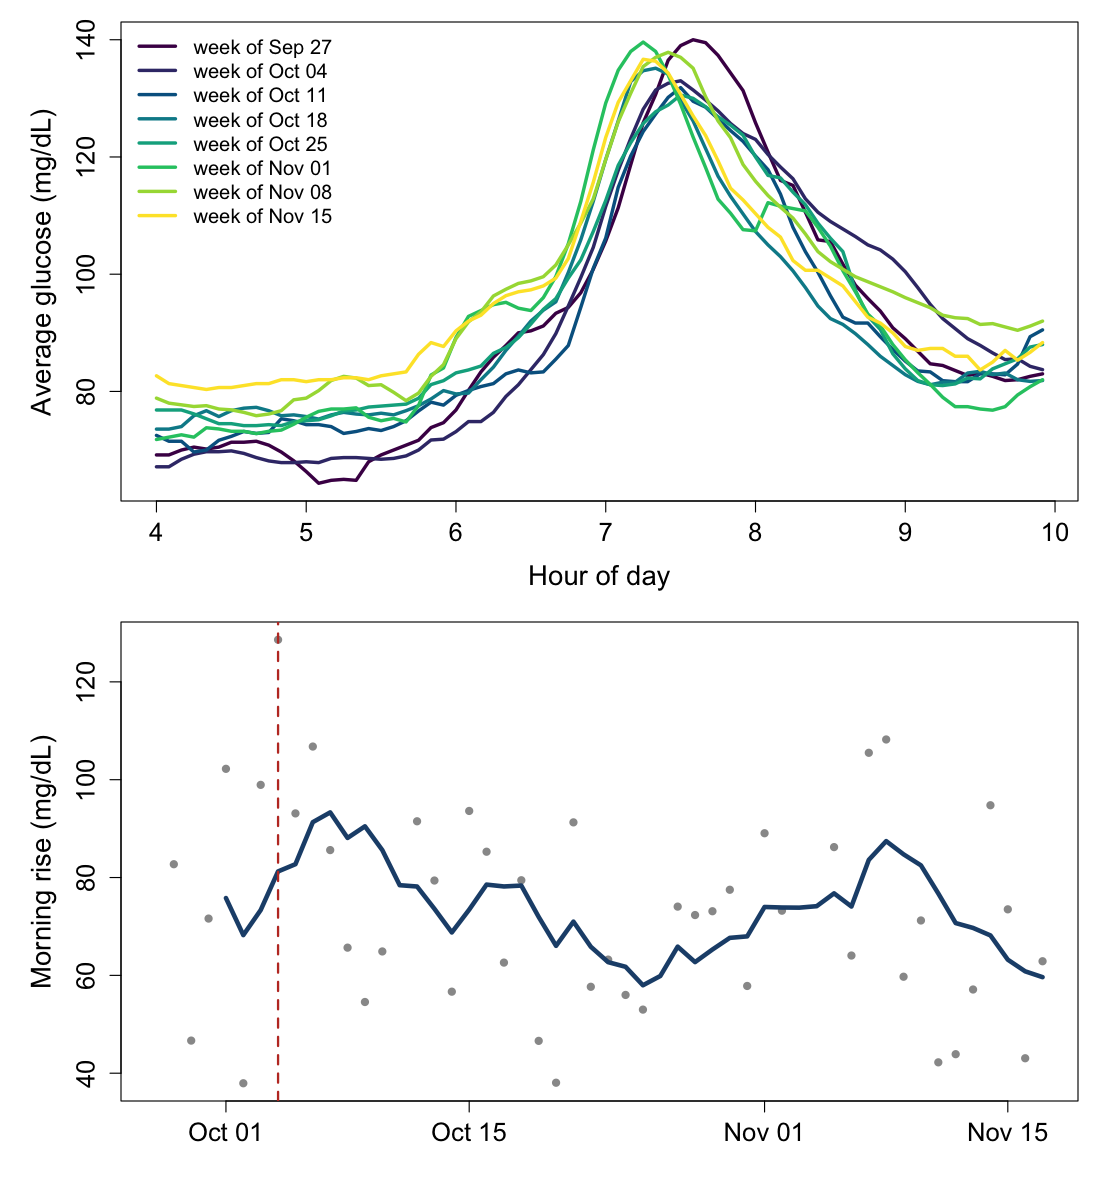

In [3]:
clock <- glucose$time - 3600 * clock_shift_hours * (as.Date(glucose$time) >= as.Date("2026-11-01"))
hour  <- as.integer(format(clock, "%H")) + as.integer(format(clock, "%M")) / 60
week  <- as.Date("2026-09-27") + 7 * (as.integer(as.Date(clock) - as.Date("2026-09-27")) %/% 7)
inside <- hour >= 4 & hour < 10
slot <- floor(hour[inside] * 12) / 12
curves <- tapply(glucose$glucose[inside], list(slot, format(week[inside])), mean)
colours <- hcl.colors(ncol(curves), "viridis")

par(mfrow = c(2, 1), mar = c(4.5, 5.5, 1, 1))
matplot(as.numeric(rownames(curves)), curves, type = "l", lty = 1, lwd = 3, col = colours,
        xlab = "Hour of day", ylab = "Average glucose (mg/dL)", cex.lab = 1.5, cex.axis = 1.4)
legend("topleft", bty = "n", lwd = 3, col = colours, cex = 1.1,
       legend = paste("week of", format(as.Date(colnames(curves)), "%b %d")))

days <- seq(as.Date("2026-09-27"), as.Date("2026-11-17"), by = 1)
rise <- mornings$rise[match(days, mornings$day)]
rise7 <- moving_average(ifelse(is.na(rise), 0, rise), !is.na(rise))
plot(days, rise, pch = 16, col = "gray60", xlab = "", ylab = "Morning rise (mg/dL)",
     cex.lab = 1.5, cex.axis = 1.4)
lines(days, rise7, lwd = 4, col = "#1f4e79")
abline(v = as.Date("2026-10-04"), lty = 2, lwd = 2, col = "#c0392b")

**Explanation**

* The first four lines move the clock times in the same way as `morning_summary`, then give each reading its hour and its week.
* `inside` is TRUE for readings from 04:00 to 09:59. `slot` rounds each of these down to its 5 minute step. `floor(x)` rounds down.
* `tapply(values, list(slot, week), mean)` takes the mean glucose in each 5 minute step of each week. `hcl.colors(n, "viridis")` picks n colours that run from dark to light, so later weeks are lighter.
* `matplot(...)` draws one line for each column of `curves`, which is one line per week. `legend(...)` names the weeks.
* In the lower plot `match(days, mornings$day)` puts each morning's rise on its calendar day, leaving a gap where a morning is missing. The blue line is the 7 day moving average of the rise, using only the days with a rise (see notebook weekly_trends). The red dashed line is 2026-10-04, when Vimpat was started (date from the caregiver).

## Step 4. See what the clock choice changes

In [4]:
as_written <- morning_summary(glucose, clock_shift_hours = 0)
moved      <- morning_summary(glucose, clock_shift_hours = 1)
peak_time <- data.frame(week = format(sort(unique(moved$week))),
                        as_written = round(tapply(as_written$peak_hour, as_written$week, mean), 1),
                        moved_1_hour = round(tapply(moved$peak_hour, moved$week, mean), 1))
peak_time

                 week as_written moved_1_hour
2026-09-27 2026-09-27        7.6          7.6
2026-10-04 2026-10-04        7.8          7.8
2026-10-11 2026-10-11        7.6          7.6
2026-10-18 2026-10-18        7.3          7.3
2026-10-25 2026-10-25        7.5          7.5
2026-11-01 2026-11-01        8.5          7.5
2026-11-08 2026-11-08        8.6          7.6
2026-11-15 2026-11-15        8.4          7.4


**Explanation**

* We run `morning_summary` twice: once with the times as written (`clock_shift_hours = 0`) and once with times from 2026-11-01 on moved 1 hour earlier.
* `tapply(values, week, mean)` takes the mean peak time in each week, and `round(..., 1)` rounds it to one decimal place.
* `data.frame(...)` puts the two columns side by side, one row per week.

**Result.** With the times as written, the average peak time jumps from 7.5 in the week of 2026-10-25 to 8.5, 8.6 and 8.4 in the three weeks from 2026-11-01. With the move of 1 hour, it stays between 7.3 and 7.8 in all 8 weeks. This agrees with notebook time_of_day. Both checks assume the morning routine stayed the same, so a known clock time would still settle the question.